# LangChain MCP 클라이언트 연동

**이 노트북에서 할 일**

1. 서버의 MCP 도구를 `MCPAdapter`로 LangChain 도구로 바꾸고, 바뀐 도구의 모양을 모델 없이 봅니다.
2. 바뀐 도구를 부르는 방법과, 부를 때마다 서버 프로세스가 떴다가 끝나는지를 봅니다.
3. 도구 실행 노드와 에이전트에 MCP 도구를 붙이고, 에이전트를 실제 모델로 한 번 실행합니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 5절에서 에이전트를 한 번 실행합니다.
에이전트가 MCP 도구를 한 번 부르고 답하면, 모델 요청은 2번입니다.
호출 한도 3을 붙여, 요청이 끝없이 늘지 않게 막습니다.
요금표로 어림한 예상 비용은 0.001달러 아래이고, 청구 금액이 아닙니다.

2~4절은 모델을 부르지 않고, 출력은 서버와 도구가 주고받은 값입니다.
모델이 쓰는 도구 인자와 답 글은 실행마다 달라질 수 있습니다.
서버는 실습 폴더 맨 위의 서버 파일 `course_server.py`를 자식 프로세스로 띄웁니다.
노트북이 쓰는 파일은 없고, 걸린 시간은 재지 않았습니다.
앞에서 배운 함수 다섯은 도구 파일 `connect_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 여덟을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langgraph 1.2.11입니다.
패키지 langchain-openai 1.6.0, fastmcp 4.0.3, mcp 2.2.0도 설치합니다.
나머지 둘은 psutil 7.2.2와 python-dotenv 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었고, 다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~3절을 읽습니다.
MCP 도구가 LangChain 도구로 바뀐 모양과, 비동기로만 부를 수 있는 까닭을 보는 자리입니다.
4~5절은 도구 실행 노드와 에이전트에 붙여 실행하는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch28-mcp`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 서버 파일 course_server.py 도구 lookup_policy에서 파란 상자 stdio_config 설정 한 벌 keep_alive False로, 거기서 파란 상자 MCPAdapter list_tools로 화살표가 갑니다. 그 아래 노란 상자 StructuredTool lookup_policy 입력 형식 dict ainvoke로만 부름으로 화살표가 가고, 그 상자에서 점선 화살표 둘이 나란히 놓인 파란 상자 ToolNode 도구 실행 노드와 파란 상자 create_agent 에이전트로 가는 그림](attachment:04-1-MCP-도구가-LangChain-도구가-되기까지.png)

위에서 아래로 읽습니다.
초록 상자는 서버 파일이고, 파란 상자는 우리가 부른 함수와 클래스입니다.
노란 상자는 노트북 2·3절 출력으로 확인한 바뀐 도구의 모양입니다.
맨 아래 점선 둘은 같은 도구를 붙인 두 곳이고, 4절과 5절에서 차례로 씁니다.
모델은 5절에서만 부르고, 이 그림에는 모델 상자를 두지 않았습니다.
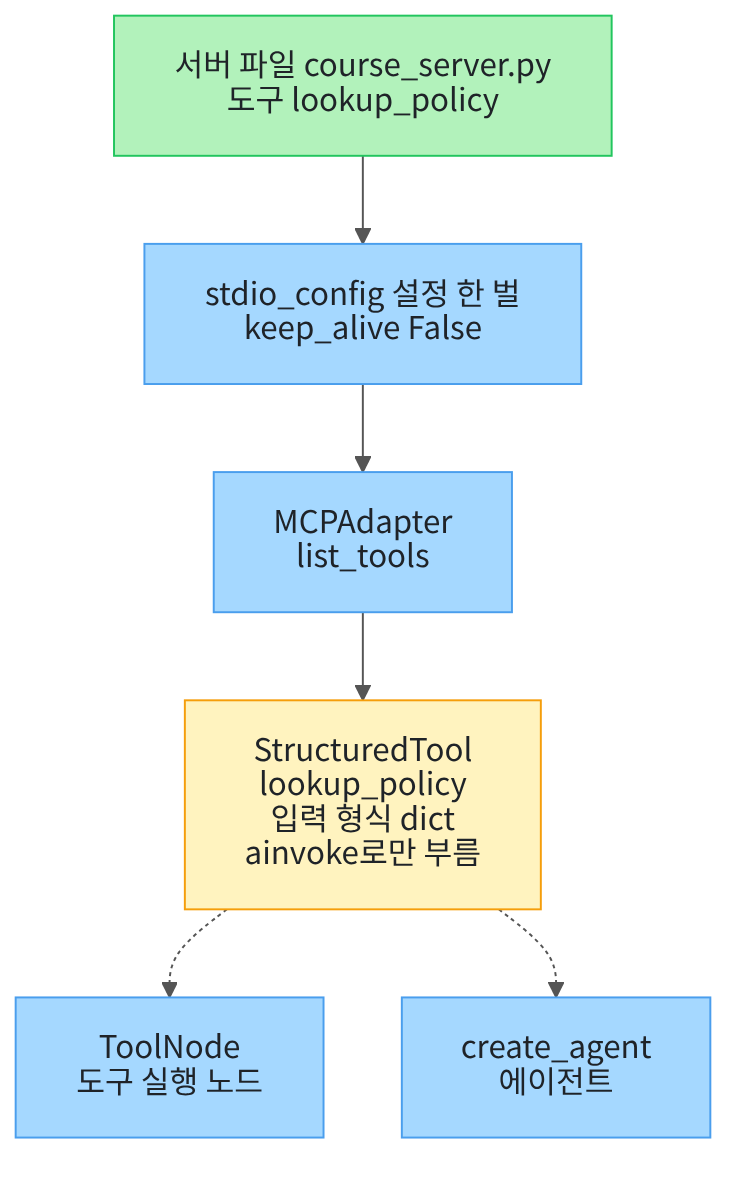

## 1. 준비

제목의 LangChain MCP는 langchain 1.4.0에 든 모듈 `langchain.mcp`를 가리킵니다.
그 안의 클래스 `MCPAdapter`가 MCP 서버에 붙어, 서버의 도구를 LangChain 도구로 바꿉니다.
바꾼 도구는 Ch 20의 도구 실행 노드와 Ch 21의 에이전트에 넘길 수 있습니다.

첫 셀은 패키지 여덟을 설치하고 설치된 판 번호를 출력합니다.
패키지 psutil은 03절에서 자식 프로세스 수를 센 패키지입니다.
패키지 langgraph는 Ch 20에서 도구 실행 노드를 가져온 패키지입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain[mcp]==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "langgraph==1.2.11" "fastmcp==4.0.3" "mcp==2.2.0" "psutil==7.2.2" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("fastmcp:", version("fastmcp"))
print("mcp:", version("mcp"))
print("psutil:", version("psutil"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langgraph: 1.2.11
fastmcp: 4.0.3
mcp: 2.2.0
psutil: 7.2.2
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`, `langgraph: 1.2.11`, `fastmcp: 4.0.3`, `psutil: 7.2.2`가 보입니다.
여덟 판 모두 실습 폴더 잠금과 같습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `langchain.mcp`는 아직 베타라서, 가져올 때 경고 `LangChainBetaWarning`을 한 번 냅니다.
그 경고 줄에는 실행마다 바뀌는 임시 파일 이름이 들어 있습니다.
그래서 모듈 `warnings`의 함수 `filterwarnings`로 이 경고 한 종류만 끄고 가져옵니다.
상태 형식 `MessagesState`는 LangGraph가 미리 만들어 둔 형식이고, 4절에서 풉니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(langchain.mcp는 베타 경고 한 종류만 끄고 가져옵니다)
import warnings
import psutil
from langchain_core._api import LangChainBetaWarning
warnings.filterwarnings("ignore", category=LangChainBetaWarning)
from langchain.mcp import MCPAdapter
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, HumanMessage
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode
# 01·03절과 앞 챕터에서 배운 함수 다섯은 도구 파일에서 가져옵니다
from connect_tools import estimate_cost, names_of, stdio_config, sum_usage, tool_call_names

print("도구 파일에서 가져온 함수:", "estimate_cost, names_of, stdio_config, sum_usage, tool_call_names")

도구 파일에서 가져온 함수: estimate_cost, names_of, stdio_config, sum_usage, tool_call_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, names_of, stdio_config, sum_usage, tool_call_names`가 보입니다.
함수 `names_of`는 01절 4절에서 만든 함수로, 목록의 항목마다 이름을 모읍니다.
함수 `stdio_config`는 03절 2절에서 만든 함수로, 서버 파일 하나를 stdio로 띄우는 설정 한 벌을 만듭니다.
나머지 셋은 Ch 19 04·05절과 Ch 6 06절에서 배운 함수이고, 4·5절에서 씁니다.

함수 `stdio_config`와 앞 챕터 함수 셋은 이 절부터 도구 파일에서 가져옵니다.
앞 챕터 함수 셋은 Ch 21 도구 파일 `runner_tools.py`의 함수와 설명 주석·본문이 같습니다.
그 파일은 이 실습 폴더에 없는 패키지를 가져와서, 파일째 가져오지 않고 함수만 옮겼습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 5절 실행 셀에서만 나갑니다.

## 2. MCP 도구를 LangChain 도구로 바꾸기

03절까지는 FastMCP의 클래스 `Client`로 서버의 도구를 직접 불렀습니다.
이 절은 같은 서버의 도구를 LangChain 도구로 바꿔, Ch 20·21의 그래프와 에이전트에 붙입니다.
먼저 01절 2절과 같은 셀로 서버 파일의 위치를 찾습니다.

In [5]:
# 작업 폴더에서 본 서버 파일의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["../course_server.py", "course_server.py", "labs/part6/ch28-mcp/course_server.py"]
server_file = None
for candidate in candidates:
    if os.path.exists(candidate):
        server_file = candidate
        break
print("서버 파일을 찾았는가:", server_file is not None)
print("고른 파일 위치:", server_file)
assert server_file is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

서버 파일을 찾았는가: True
고른 파일 위치: labs/part6/ch28-mcp/course_server.py


**결과 읽기** — 출력 줄 `서버 파일을 찾았는가: True`가 보입니다.
교재 출력은 프로젝트 맨 위에서 실행해 셋째 후보 `labs/part6/ch28-mcp/course_server.py`를 골랐습니다.
`notebooks/` 폴더에서 열면 첫 후보 `../course_server.py`가 골라집니다.

다음 셀은 03절 2절과 같은 셀로, 서버를 조용히 띄우는 환경 변수 셋을 딕셔너리로 만듭니다.

In [6]:
# 자식 프로세스로 띄운 FastMCP 서버가 시작 안내와 새 판 확인을 하지 않게 하는 환경 변수 셋입니다
quiet_env = {
    "FASTMCP_SHOW_SERVER_BANNER": "false",
    "FASTMCP_CHECK_FOR_UPDATES": "off",
    "FASTMCP_LOG_LEVEL": "WARNING",
}
print("조용히 하는 이름:", list(quiet_env))

조용히 하는 이름: ['FASTMCP_SHOW_SERVER_BANNER', 'FASTMCP_CHECK_FOR_UPDATES', 'FASTMCP_LOG_LEVEL']


**결과 읽기** — 라벨 `조용히 하는 이름:` 뒤에 이름 셋이 보입니다.
03절에서 본 것처럼, 시작 안내와 새 판 확인을 끄고 기록 수준을 올리는 이름입니다.

다음 셀은 03절 함수 `stdio_config`로 설정 한 벌을 만들어, 클래스 `MCPAdapter`에 넘깁니다.
칸 `keep_alive`가 `False`인 설정이라, 연결을 닫으면 서버도 끝납니다.
메서드 `list_tools`는 서버에 연결해 도구 목록을 받습니다.
받은 도구를 하나씩 LangChain 도구로 바꿔, 그 목록을 내놓습니다.
연결은 이 메서드 안에서 열고 닫으므로, `async with` 블록 없이 `await`만 붙여 부릅니다.

In [7]:
# 03절 함수 stdio_config로 만든 설정 한 벌을 MCPAdapter에 넘기고, 도구 목록을 LangChain 도구로 받습니다
kernel_process = psutil.Process()
course_config = stdio_config(server_file, quiet_env)
adapter = MCPAdapter(course_config)
mcp_tools = await adapter.list_tools()
children_after = kernel_process.children()
print("받은 도구 이름:", names_of(mcp_tools))
print("목록을 받은 뒤 자식 프로세스 수:", len(children_after))

받은 도구 이름: ['lookup_policy']
목록을 받은 뒤 자식 프로세스 수: 0


**결과 읽기** — 출력 줄 `받은 도구 이름: ['lookup_policy']`가 보입니다.
03절에서 클래스 `Client`로 받은 도구와 같은 이름입니다.
출력 줄 `목록을 받은 뒤 자식 프로세스 수: 0`으로, 목록을 받는 동안 띄운 서버도 끝났습니다.

다음 셀은 바뀐 도구 하나의 종류·설명·입력 형식을 봅니다.
속성 `args_schema`는 도구의 입력 형식을 담는 칸입니다.

In [8]:
# 바뀐 도구 하나의 종류·설명·입력 형식을 봅니다
policy_tool = mcp_tools[0]
print("도구 종류:", type(policy_tool).__name__)
print("설명:", policy_tool.description)
print("입력 형식의 종류:", type(policy_tool.args_schema).__name__)
print("입력 형식:", policy_tool.args_schema)

도구 종류: StructuredTool
설명: 자료실 규정을 조회합니다. topic은 대출, 운영, 연체 중 하나입니다.
입력 형식의 종류: dict
입력 형식: {'type': 'object', 'additionalProperties': False, 'properties': {'topic': {'type': 'string'}}, 'required': ['topic']}


**결과 읽기** — 출력 줄 `도구 종류: StructuredTool`이 보입니다.
Ch 19 01절에서 `@tool` 줄로 만든 도구와 같은 종류입니다.
설명은 서버 파일 도구의 독스트링 글 그대로입니다.
출력 줄 `입력 형식의 종류: dict`로, 입력 형식은 딕셔너리입니다.
라벨 `입력 형식:` 뒤의 글은 01절 4절에서 본 서버의 입력 형식과 글자까지 같습니다.

Ch 19 02절은 입력 형식을 양식 클래스 `BaseModel`로 적었습니다.
바뀐 MCP 도구는 서버가 보낸 입력 형식을 딕셔너리 그대로 들고 있습니다.
모델에게 보내는 도구 정의에 이 딕셔너리가 어떻게 실리는지는 05절에서 봅니다.

다음 셀은 도구가 내놓는 값의 모양과, 도구에 붙은 서버 정보를 봅니다.
속성 `response_format`은 도구가 내놓는 값을 어떤 모양으로 나눌지 정합니다.
속성 `metadata`는 도구에 붙여 둔 정보를 담는 딕셔너리입니다.

In [9]:
# 도구가 내놓는 값의 모양과, 도구에 붙은 서버 정보·꼬리표를 봅니다
print("내놓는 값의 모양:", policy_tool.response_format)
mcp_info = policy_tool.metadata["mcp"]
tool_meta = mcp_info["tool"]["_meta"]
print("서버 정보:", mcp_info["server"])
print("꼬리표:", tool_meta["fastmcp"]["tags"])

내놓는 값의 모양: content_and_artifact
서버 정보: {'name': '교육센터 자료실', 'version': '4.0.3'}
꼬리표: ['public', 'read']


**결과 읽기** — 출력 줄 `내놓는 값의 모양: content_and_artifact`가 보입니다.
도구가 내놓는 값을 모델에게 보낼 내용과, 메시지에만 붙여 둘 아티팩트로 나눈다는 뜻입니다.
라벨 `서버 정보:` 뒤에 서버 이름 `교육센터 자료실`과 판 `4.0.3`이 보입니다.
출력 줄 `꼬리표: ['public', 'read']`는 서버 파일이 도구를 붙이며 적은 꼬리표입니다.
02절 6절에서 본 꼬리표와 같습니다.

## 3. 비동기로만 부르는 도구

Ch 19 01절에서는 도구의 메서드 `invoke`에 인자 딕셔너리를 넣어 불렀습니다.
바뀐 MCP 도구도 같은 방법으로 불러 봅니다.
오류가 나면 이름 `NotImplementedError`만 받아, 셀이 멈추지 않게 합니다.
실행 전에 예상해 봅니다.
이 도구도 `invoke`로 부를 수 있을까요?

In [10]:
# Ch 19 01절처럼 .invoke로 불러 봅니다(오류 NotImplementedError만 받습니다)
try:
    policy_tool.invoke({"topic": "운영"})
except NotImplementedError as error:
    print("받은 것:", type(error).__name__)
    print("받은 글:", str(error))

받은 것: NotImplementedError
받은 글: StructuredTool does not support sync invocation.


**결과 읽기** — 받은 것은 `NotImplementedError`이고, 받은 글은 `StructuredTool does not support sync invocation.`입니다.
받은 글의 sync invocation은 비동기가 아닌 보통 부르기를 뜻합니다.
이 도구는 보통 부르기로는 쓸 수 없다는 뜻입니다.

바뀐 MCP 도구는 서버와 메시지를 주고받는 비동기 함수 하나만 몸통으로 들고 있습니다.
그래서 메서드 `ainvoke`로 불러야 하고, `ainvoke`는 `invoke`의 비동기 판입니다.
01절에서 본 것처럼, 노트북 셀 맨 위에서는 `await`를 붙여 끝날 때까지 기다립니다.
다음 셀은 같은 인자를 `ainvoke`에 넘겨 부르고, 부른 뒤 자식 프로세스 수를 셉니다.

In [11]:
# 비동기 판 ainvoke로 같은 인자를 넘겨 부르고, 부른 뒤 자식 프로세스 수를 셉니다
operation_blocks = await policy_tool.ainvoke({"topic": "운영"})
children_now = kernel_process.children()
first_block = operation_blocks[0]
print("받은 값의 종류:", type(operation_blocks).__name__)
print("내용 블록 수:", len(operation_blocks))
print("첫 블록의 키:", list(first_block))
print("첫 블록의 종류:", first_block["type"])
print("첫 블록의 글:", first_block["text"])
print("부른 뒤 자식 프로세스 수:", len(children_now))

받은 값의 종류: list
내용 블록 수: 1
첫 블록의 키: ['type', 'text', 'id']
첫 블록의 종류: text
첫 블록의 글: 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.
부른 뒤 자식 프로세스 수: 0


**결과 읽기** — 출력 줄 `받은 값의 종류: list`와 `내용 블록 수: 1`이 보입니다.
라벨 `첫 블록의 글:` 뒤의 글은 서버 파일의 운영 규정 글 그대로입니다.
출력 줄 `부른 뒤 자식 프로세스 수: 0`으로, 이번 호출이 띄운 서버도 끝났습니다.
앞 셀까지 0이었으니, 부를 때 서버가 새로 떠서 답하고 끝났습니다.

인자 딕셔너리로 부르면, 도구는 모델에게 보낼 내용만 내놓습니다.
그 내용은 내용 블록의 목록이고, 블록 하나는 종류와 글을 담은 딕셔너리입니다.
라벨 `첫 블록의 키:` 뒤의 `id`는 LangChain이 블록마다 새로 붙이는 번호라, 실행마다 값이 바뀝니다.
그래서 이 절은 블록 전체 대신 글 `text`만 출력합니다.

LangChain 문서는 바꾼 도구가 부를 때마다 연결을 열고 닫는다고 적습니다.
연결 블록 `async with adapter:` 안에서 부르면, 블록이 연 연결을 그대로 씁니다.
다음 셀은 블록 안에서 같은 도구를 부르고, 부르기 전과 뒤의 자식 프로세스를 견줍니다.
속성 `pid`는 운영체제가 프로세스마다 붙인 번호입니다.
번호는 실행마다 달라 출력하지 않고, 두 번호가 같은지만 봅니다.

In [12]:
# 연결 블록 안에서 같은 도구를 부르고, 부르기 전과 뒤의 자식 프로세스를 견줍니다
async with adapter:
    children_before_call = kernel_process.children()
    overdue_blocks = await policy_tool.ainvoke({"topic": "연체"})
    children_after_call = kernel_process.children()
children_now = kernel_process.children()
print("블록 안, 부르기 전 자식 프로세스 수:", len(children_before_call))
print("블록 안, 부른 뒤 자식 프로세스 수:", len(children_after_call))
print("같은 프로세스인가:", children_before_call[0].pid == children_after_call[0].pid)
print("블록을 벗어난 뒤 자식 프로세스 수:", len(children_now))

블록 안, 부르기 전 자식 프로세스 수: 1
블록 안, 부른 뒤 자식 프로세스 수: 1
같은 프로세스인가: True
블록을 벗어난 뒤 자식 프로세스 수: 0


**결과 읽기** — 출력 줄 `블록 안, 부르기 전 자식 프로세스 수: 1`과 `블록 안, 부른 뒤 자식 프로세스 수: 1`이 보입니다.
출력 줄 `같은 프로세스인가: True`로, 블록이 띄운 서버 하나가 도구 호출을 받았습니다.
출력 줄 `블록을 벗어난 뒤 자식 프로세스 수: 0`으로, 블록을 벗어나자 그 서버도 끝났습니다.

블록 밖에서는 부를 때마다 서버가 떴다가 끝났고, 블록 안에서는 서버 하나를 이어 썼습니다.
어느 쪽이든 칸 `keep_alive`가 `False`라, 연결이 모두 닫히면 남는 서버가 없습니다.

## 4. 도구 실행 노드에 손으로 만든 요청 넣기

Ch 20 01절은 모델 대신 도구 호출 요청을 담은 응답을 손으로 만들어 그래프를 살폈습니다.
이 절도 같은 방법으로, 바뀐 MCP 도구를 도구 실행 노드 `ToolNode`에 넣어 봅니다.
그래프의 상태 형식은 LangGraph가 미리 만들어 둔 `MessagesState`를 씁니다.
Ch 21 03절의 `AgentState`보다 칸이 적어, 칸 `messages` 하나만 둔 형식입니다.
그 칸에는 Ch 13 04절의 `add_messages` 규칙이 붙어 있습니다.

다음 셀은 도구 실행 노드 하나만 둔 그래프를 만듭니다.

In [13]:
# MCP 도구 목록으로 도구 실행 노드 하나만 둔 그래프를 만듭니다(Ch 20 01절 ToolNode)
builder = StateGraph(MessagesState)
builder.add_node("tools", ToolNode(mcp_tools))
builder.add_edge(START, "tools")
builder.add_edge("tools", END)
tool_graph = builder.compile()
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['tools']


**결과 읽기** — 출력 줄 `등록한 노드: ['tools']`가 보입니다.
Ch 20 01절과 달리 모델 노드가 없고, 시작 엣지와 끝 엣지 사이에 도구 실행 노드만 있습니다.

다음 셀은 모델 대신 도구 호출 요청 둘을 담은 응답 하나를 손으로 만듭니다.
첫 요청에는 주제어 운영을, 둘째 요청에는 서버 규정에 없는 주제어 주차를 넣습니다.
호출 ID `call_a`·`call_b`는 이 셀에서 정한 글입니다.

In [14]:
# 모델 대신, 도구 호출 요청 둘을 담은 응답 하나를 손으로 만듭니다(Ch 20 01절 모양)
good_call = {"name": "lookup_policy", "args": {"topic": "운영"}, "id": "call_a", "type": "tool_call"}
# 둘째 요청의 주제어 주차는 서버 파일의 규정에 없는 주제어입니다
bad_call = {"name": "lookup_policy", "args": {"topic": "주차"}, "id": "call_b", "type": "tool_call"}
hand_request = AIMessage(content="", tool_calls=[good_call, bad_call])
print("도구 호출 요청:", tool_call_names(hand_request))

도구 호출 요청: ['lookup_policy', 'lookup_policy']


**결과 읽기** — 출력 줄 `도구 호출 요청: ['lookup_policy', 'lookup_policy']`가 보입니다.
Ch 19 04절 함수 `tool_call_names`로 이름만 모았고, 같은 도구를 두 번 부르는 응답입니다.

다음 셀은 이 응답 하나를 메시지 칸에 넣어 그래프를 실행합니다.
도구가 비동기로만 불리므로, 그래프도 `invoke` 대신 `ainvoke`로 실행합니다.
실행 전에 예상해 봅니다.
서버 규정에 없는 주제어를 넣은 요청은 어떻게 될까요?

In [15]:
# 손으로 만든 응답을 넣어 그래프를 비동기 판 ainvoke로 실행하고, 메시지 종류를 차례로 봅니다
graph_result = await tool_graph.ainvoke({"messages": [hand_request]})
graph_messages = graph_result["messages"]
children_now = kernel_process.children()
print("메시지 종류:")
for message in graph_messages:
    print(type(message).__name__)
print("실행 뒤 자식 프로세스 수:", len(children_now))

메시지 종류:
AIMessage
ToolMessage
ToolMessage
실행 뒤 자식 프로세스 수: 0


**결과 읽기** — 라벨 `메시지 종류:` 줄 아래에 `AIMessage` 하나와 `ToolMessage` 둘이 차례로 보입니다.
도구 실행 노드가 요청마다 도구 메시지 하나를 이어 붙였습니다.
출력 줄 `실행 뒤 자식 프로세스 수: 0`으로, 두 요청을 처리한 서버도 모두 끝났습니다.

다음 셀은 도구 메시지마다 호출 ID·결과 상태·글을 봅니다.
속성 `text`는 메시지 내용 가운데 글만 이어 붙여 내놓습니다.
내용 블록의 `id`는 실행마다 바뀌므로, 내용 전체 대신 이 속성을 출력합니다.

In [16]:
# 도구 메시지마다 호출 ID·결과 상태·글을 봅니다(내용 블록의 id는 실행마다 달라 출력하지 않습니다)
for message in graph_messages[1:]:
    print("호출 ID:", message.tool_call_id, "| 결과 상태:", message.status)
    print("글:", message.text)

호출 ID: call_a | 결과 상태: success
글: 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.
호출 ID: call_b | 결과 상태: error
글: Error calling tool 'lookup_policy': topic은 대출, 운영, 연체 중 하나여야 합니다.


**결과 읽기** — 출력 줄 `호출 ID: call_a | 결과 상태: success`와 `호출 ID: call_b | 결과 상태: error`가 보입니다.
첫 메시지의 글은 운영 규정 글이고, 둘째 메시지의 글은 서버가 낸 오류 글입니다.
오류 글 `Error calling tool 'lookup_policy': topic은 대출, 운영, 연체 중 하나여야 합니다.`는 02절 6절에서 본 글과 같습니다.

서버 쪽 도구가 오류를 냈어도 셀은 멈추지 않았습니다.
Ch 19 06절에서는 도구 속성 `handle_tool_error`를 두어 오류를 결과 상태 `error`의 도구 메시지로 받았습니다.
클래스 `MCPAdapter`가 바꾼 도구에는 이 속성이 미리 채워져 있습니다.
그래서 서버의 오류 글이 도구 메시지에 담겨, 에이전트라면 다음 모델 요청에 실립니다.

도구 메시지에는 내용 말고도 아티팩트(artifact)라는 칸이 있습니다.
다음 셀은 두 도구 메시지의 아티팩트를 봅니다.

In [17]:
# 두 도구 메시지의 아티팩트(모델에게 보내지 않고 메시지에 붙여 두는 값)를 봅니다
success_message = graph_messages[1]
error_message = graph_messages[2]
print("성공한 메시지의 아티팩트:", success_message.artifact)
print("오류 메시지의 아티팩트:", error_message.artifact)

성공한 메시지의 아티팩트: {'structured_content': {'result': '평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.'}}
오류 메시지의 아티팩트: None


**결과 읽기** — 라벨 `성공한 메시지의 아티팩트:` 뒤에 딕셔너리 하나가 보입니다.
칸 `structured_content` 안의 칸 `result`에 운영 규정 글이 들어 있습니다.
출력 줄 `오류 메시지의 아티팩트: None`으로, 오류 메시지에는 아티팩트가 없습니다.

02절 6절에서 본 서버 파일 도구의 출력 형식이 바로 이 칸 `result`입니다.
패키지 langchain-core의 `ToolMessage` 설명은 아티팩트를 모델에게 보내지 않는 값이라고 적습니다.

## 5. 에이전트에 MCP 도구 붙이기

이제 바꾼 도구를 에이전트에 붙이고, 실제 모델로 한 번 실행합니다.
Ch 21 01절처럼 함수 `create_agent`에 모델 객체와 도구 목록을 넘깁니다.
Ch 26·27처럼 모델을 부르는 에이전트에는 Ch 22 04절의 호출 한도를 함께 붙입니다.
다음 셀은 invoke 한 번에 모델 요청을 3번까지만 허락하는 호출 한도를 만듭니다.

In [18]:
# invoke 한 번에 모델 요청을 3번까지만 허락하는 호출 한도를 만듭니다(Ch 22 04절)
call_limit = ModelCallLimitMiddleware(run_limit=3, exit_behavior="end")
print("한 번 실행의 요청 한도:", call_limit.run_limit)
print("한도에 닿으면:", call_limit.exit_behavior)

한 번 실행의 요청 한도: 3
한도에 닿으면: end


**결과 읽기** — 출력 줄 `한 번 실행의 요청 한도: 3`과 `한도에 닿으면: end`가 보입니다.
한도에 닿으면 모델을 더 부르지 않고 실행을 끝낸다는 뜻입니다.
이 한도는 `ainvoke`로 실행해도 실행 한 번마다 셉니다.

다음 셀은 모델 객체·MCP 도구·시스템 메시지 글·호출 한도로 에이전트를 만듭니다.
시스템 메시지 글에는 규정 질문에 도구로 규정을 찾으라는 규칙을 적습니다.
이 셀은 에이전트를 만들기만 하고, 모델 요청은 보내지 않습니다.

In [19]:
# 모델 객체·MCP 도구·시스템 메시지 글·호출 한도로 에이전트를 만듭니다(Ch 21 01절, 요청은 아직 없음)
agent_rule = "교육센터 자료실 규정 질문에는 도구로 규정을 찾아, 찾은 글만 근거로 한국어 한 문장으로 답하세요."
mcp_agent = create_agent(model, tools=mcp_tools, system_prompt=agent_rule, middleware=[call_limit])
agent_graph = mcp_agent.get_graph()
print("노드:", list(agent_graph.nodes))

노드: ['__start__', 'model', 'tools', 'ModelCallLimitMiddleware.before_model', 'ModelCallLimitMiddleware.after_model', '__end__']


**결과 읽기** — 라벨 `노드:` 뒤에 노드 여섯의 이름이 보입니다.
모델 노드 `model`과 도구 실행 노드 `tools` 옆에, 호출 한도의 훅 노드 둘이 들어 있습니다.

다음 셀은 질문 한 줄을 넣어 에이전트를 한 번 실행합니다.
에이전트의 도구가 비동기로만 불리므로, 에이전트도 `ainvoke`로 실행합니다.
실행 전에 예상해 봅니다.
모델은 MCP 도구를 부를까요, 그리고 모델 요청은 몇 번일까요?

In [20]:
# 질문 한 줄을 넣어 에이전트를 비동기 판 ainvoke로 한 번 실행합니다(도구를 한 번 부르면 모델 요청 2번)
question = "교육센터 자료실은 토요일에 몇 시까지 운영하나요?"
first_input = {"messages": [HumanMessage(content=question)]}
agent_result = await mcp_agent.ainvoke(first_input)
agent_messages = agent_result["messages"]
children_now = kernel_process.children()
print("결과 메시지 수:", len(agent_messages))
print("실행 뒤 자식 프로세스 수:", len(children_now))

결과 메시지 수: 4
실행 뒤 자식 프로세스 수: 0


**결과 읽기** — 출력 줄 `결과 메시지 수: 4`와 `실행 뒤 자식 프로세스 수: 0`이 보입니다.
에이전트가 도구를 부르는 동안 띄운 서버도, 실행이 끝났을 때 남아 있지 않았습니다.

결과 메시지 수는 모델이 도구를 몇 번 부르느냐에 따라 달라질 수 있는 값입니다.
노트북 밖에서 같은 실행을 다섯 번 보냈을 때도 결과 메시지는 넷이었습니다.

다음 셀은 결과 메시지를 차례로 보며 종류와 도구 호출 요청 이름, 결과 상태를 출력합니다.
Ch 19 06절 함수 `show_messages`는 도구 메시지의 내용을 통째로 출력합니다.
MCP 도구 메시지의 내용에는 실행마다 바뀌는 `id`가 들어 있어, 이 셀은 내용을 빼고 출력합니다.

In [21]:
# 결과 메시지를 차례로 보며, 응답이면 도구 호출 요청 이름을, 도구 메시지면 결과 상태를 출력합니다
for message in agent_messages:
    kind = type(message).__name__
    if kind == "HumanMessage":
        print(kind)
    if kind == "AIMessage":
        print(kind, "| 도구 호출 요청:", tool_call_names(message))
    if kind == "ToolMessage":
        print(kind, "| 결과 상태:", message.status)

HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success
AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `AIMessage | 도구 호출 요청: ['lookup_policy']` 다음에 `ToolMessage | 결과 상태: success`가 보입니다.
마지막 줄은 `AIMessage | 도구 호출 요청: []`입니다.
모델이 첫 응답에서 MCP 도구를 한 번 요청했고, 도구 실행 노드가 그 도구를 불렀습니다.
도구 메시지를 받은 모델은 둘째 응답에서 도구를 더 요청하지 않았습니다.

어느 도구를 몇 번 부를지는 모델이 고르는 값입니다.
노트북 밖에서 같은 실행을 다섯 번 보냈을 때 다섯 번 모두 이 차례였습니다.

다음 셀은 모델이 쓴 도구 인자와, 도구 메시지의 글을 봅니다.
인자는 모델이 쓴 값이라 실행마다 달라질 수 있습니다.

In [22]:
# 모델이 쓴 도구 인자와, 도구 메시지의 글을 봅니다(모델이 고른 값이라 실행마다 달라질 수 있음)
for message in agent_messages:
    if type(message).__name__ == "AIMessage":
        for call in message.tool_calls:
            print("도구 인자:", call["args"])
    if type(message).__name__ == "ToolMessage":
        print("도구 메시지 글:", message.text)

도구 인자: {'topic': '운영'}
도구 메시지 글: 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.


**결과 읽기** — 라벨 `도구 인자:` 줄과 `도구 메시지 글:` 줄이 차례로 보입니다.
도구 메시지 글은 서버가 인자로 받은 주제어의 규정 글입니다.

이번 실행에서는 인자가 `{'topic': '운영'}`이었고, 받은 글은 운영 규정 글이었습니다.
노트북 밖 다섯 번과 두 커널 실행에서도 인자는 같았지만, 모델이 쓴 값이라 결론에는 쓰지 않습니다.

Ch 26·27에서는 모델 요청 수를 「도구를 요청한 응답 수 + 1」로 셌습니다.
모델은 도구를 요청할 때마다 응답을 하나 쓰고, 마지막에 답을 쓰는 응답이 하나 더 있기 때문입니다.
다음 셀은 도구를 요청한 응답 수를 세고, Ch 19 05절 함수 `sum_usage`로 센 요청 수와 견줍니다.

In [23]:
# 도구를 요청한 응답 수를 세고, Ch 19 05절 함수 sum_usage로 센 모델 요청 수와 견줍니다
asked_responses = 0
for message in agent_messages:
    if type(message).__name__ == "AIMessage":
        if len(tool_call_names(message)) > 0:
            asked_responses = asked_responses + 1
run_usage = sum_usage(agent_messages)
print("도구를 요청한 응답 수:", asked_responses)
print("모델 요청 수:", run_usage["requests"])
print("모델 요청 수 = 도구를 요청한 응답 수 + 1:", run_usage["requests"] == asked_responses + 1)

도구를 요청한 응답 수: 1
모델 요청 수: 2
모델 요청 수 = 도구를 요청한 응답 수 + 1: True


**결과 읽기** — 출력 줄 `도구를 요청한 응답 수: 1`과 `모델 요청 수: 2`가 보입니다.
출력 줄 `모델 요청 수 = 도구를 요청한 응답 수 + 1: True`로, 셈이 맞았습니다.
요청 수 2는 호출 한도 3 안에 들었습니다.

도구를 요청한 응답 수는 모델이 고르는 값이라 실행마다 달라질 수 있습니다.
셈은 호출 한도에 닿지 않고 답으로 끝난 실행에서 맞습니다.

다음 셀은 모델이 쓴 마지막 답 글을 봅니다.
답 글은 실행마다 달라질 수 있는 값입니다.

In [24]:
# 모델이 쓴 마지막 답 글을 봅니다(실행마다 달라질 수 있는 값)
final_answer = agent_messages[-1].text
print("마지막 답 글:")
print(final_answer)

마지막 답 글:
토요일은 17:00까지 운영합니다.


**결과 읽기** — 라벨 `마지막 답 글:` 줄 아래에 모델이 쓴 답이 보입니다.
시스템 메시지 글은 찾은 글만 근거로 한국어 한 문장으로 답하라고 적었습니다.

이번 실행에서는 답 글이 「토요일은 17:00까지 운영합니다」였습니다.
도구 메시지 글에 적힌 토요일의 끝 시각 17:00과 같은 시각입니다.
노트북 밖 다섯 번 가운데 한 번은 「교육센터 자료실은」으로 시작하는 다른 문장이었습니다.

다음 셀은 이번 실행의 입력·출력 토큰과 예상 비용을 봅니다.
요금은 Ch 6 06절처럼 2026-09-17 요금표의 100만 토큰당 달러입니다.
예상 비용은 요금표로 어림한 값이고, 청구 금액이 아닙니다.

In [25]:
# 입력·출력 토큰과, 2026-09-17 요금표(100만 토큰당 달러)로 어림한 예상 비용을 봅니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
run_cost = estimate_cost(run_usage, input_rate, cached_input_rate, output_rate)
rounded_cost = round(run_cost, 6)
print("입력 토큰:", run_usage["input_tokens"], "| 출력 토큰:", run_usage["output_tokens"])
print("예상 비용(달러):", rounded_cost)

입력 토큰: 430 | 출력 토큰: 32
예상 비용(달러): 0.000467


**결과 읽기** — 라벨 `입력 토큰:`과 `출력 토큰:` 뒤에 이번 실행의 토큰 수가 보입니다.
라벨 `예상 비용(달러):` 뒤에는 요금표로 어림한 비용이 보입니다.
함수 `sum_usage`가 낸 딕셔너리에는 할인되는 입력 토큰 칸이 없어, 입력 토큰을 모두 입력 요금으로 셌습니다.

이번 실행에서는 입력 토큰 430, 출력 토큰 32, 예상 비용 0.000467달러였습니다.
노트북 밖 다섯 번에서 입력 토큰은 모두 430이었고, 출력 토큰은 32와 37로 갈렸습니다.
출력 토큰과 비용은 실행마다 달라질 수 있고, 입력 토큰은 이 절의 주제가 아니라 결론에 쓰지 않습니다.
첫 요청의 입력 토큰은 05절에서 조건을 바꿔 가며 셉니다.

## 정리

1. 클래스 `MCPAdapter`가 바꾼 도구는 `StructuredTool`이고, 입력 형식은 서버가 보낸 딕셔너리였습니다.
2. 이 도구는 `ainvoke`로만 불렸고, 칸 `keep_alive`가 `False`면 부른 뒤 서버가 남지 않았습니다.
3. 서버 오류는 결과 상태 `error`의 도구 메시지가 되었고, 모델 요청 수는 「도구를 요청한 응답 수 + 1」이었습니다.

05절에서는 도구 정의가 모델의 첫 요청 입력 토큰에 얼마나 더해지는지 셉니다.